# IND320 Project Work, Part 2 - Data Sources

GitHub: [IND320-kahaland](https://github.com/kahalandkh/IND320-kahaland) \
Streamlit: [Reservoir Data App](https://ind320-kahaland-vqqy43wgawwsxmytoyb9ah.streamlit.app)

## 0. Setup and imports

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

## 1. Magasinstatistikk API

### 1.1 Retrieve reservoir data

In Part 2, the reservoir data is retrieved directly from the [NVE Magasinstatistikk API](https://biapi.nve.no/magasinstatistikk/swagger/index.html) instead of loading the local CSV file used in Part 1. The [NVE Magasinstatistikk page](https://www.nve.no/energi/analyser-og-statistikk/magasinstatistikk/) provides additional information about the dataset and the geographical area classifications used by the API. The reservoir observations are retrieved from the public endpoint using a GET request.

In [2]:
# Download the full public reservoir dataset from the NVE API
url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

# Stop waiting if the API does not respond within 60 seconds
response = requests.get(url, timeout=60)
response.raise_for_status()

data = response.json()

### 1.2 Inspect and prepare the data

The API response is converted to a pandas DataFrame and prepared using the same column names and date format as in Part 1.

In [3]:
# Convert the API response to a pandas DataFrame
df = pd.DataFrame(data)

# Rename the original column headers to the same English names used in Part 1
df = df.rename(columns={"dato_Id": "date_id",
                        "omrType": "area_type",
                        "omrnr": "area_number",
                        "iso_aar": "iso_year",
                        "iso_uke": "iso_week",
                        "fyllingsgrad": "reservoir_fill_ratio",
                        "kapasitet_TWh": "reservoir_capacity_twh",
                        "fylling_TWh": "stored_energy_twh",
                        "neste_Publiseringsdato": "next_publication_date",
                        "fyllingsgrad_forrige_uke": "previous_week_reservoir_fill_ratio",
                        "endring_fyllingsgrad": "reservoir_fill_ratio_change"})

# Convert the observation date to datetime
df["date_id"] = pd.to_datetime(df["date_id"])

df.head()

,date_id,area_type,area_number,iso_year,iso_week,reservoir_fill_ratio,reservoir_capacity_twh,stored_energy_twh,next_publication_date,previous_week_reservoir_fill_ratio,reservoir_fill_ratio_change
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


As in Part 1, `date_id` is used as the observation date and converted to datetime. `next_publication_date` is left unchanged because many earlier records contain `0001-01-01T00:00:00` as a placeholder where a publication date is not available. These historical values could in principle be reconstructed from the sequence of observations, but since `next_publication_date` is publication metadata rather than a variable central to the reservoir analysis, no artificial values are created.

In [4]:
# Check the size of the retrieved dataset
df.shape

(14913, 11)

In [5]:
# Check the date range returned by the API.
df["date_id"].min(), df["date_id"].max()

(Timestamp('1995-01-08 00:00:00'), Timestamp('2026-10-04 00:00:00'))

The API returns 14 913 rows and 11 columns, with observations from 1995-01-08 to 2026-10-04. Compared with the CSV used in Part 1, which ended on 2026-09-06, the API now includes four additional weeks of data as of 8 October 2026.

### 1.3 Geographical areas

To interpret the area codes in the reservoir data, the `HentOmråder` endpoint is used to retrieve their names and geographical descriptions.

In [6]:
# Retrieve names and descriptions of the geographical areas
areas_url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOmråder"

areas_response = requests.get(areas_url, timeout=60)
areas_response.raise_for_status()
areas = areas_response.json()

In [7]:
# Combine all area definitions returned by the API into one DataFrame.
area_info = pd.DataFrame(
    areas[0]["land"] + areas[0]["elspot"] + areas[0]["vassdrag"]
)

# Rename the API fields to English for consistency with the reservoir dataset.
area_info = area_info.rename(columns={
    "navn": "name",
    "navn_langt": "long_name",
    "beskrivelse": "description",
    "omrType": "area_type",
    "omrnr": "area_number"
})

# Reorder columns for a clearer display.
area_info = area_info[["area_type", "area_number", "name", "long_name", "description"]]

area_info

,area_type,area_number,name,long_name,description
0,NO,0,Norge,Norge,Hele landet
1,EL,1,NO 1,Elspotområde 1,Sørøst-Norge. Omfatter østlige del av Østlande...
2,EL,2,NO 2,Elspotområde 2,Sørvest-Norge. Omfatter mesteparten av Vestfol...
3,EL,3,NO 3,Elspotområde 3,Midt-Norge. Omfatter nordre og vestlige del av...
4,EL,4,NO 4,Elspotområde 4,Nord-Norge. Omfatter resten av Trøndelag og No...
5,EL,5,NO 5,Elspotområde 5,Vest-Norge. Omfatter midtre del av Vestland op...
6,VASS,1,VASS1,Vassdragsområde 1,"Sørøst-Norge. Østlandet, Agder og deler av Rog..."
7,VASS,2,VASS2,Vassdragsområde 2,Vest-Norge. Resten av Rogaland og Vestland.
8,VASS,3,VASS3,Vassdragsområde 3,"Midt-Norge. Møre og Romsdal, Trøndelag og sørl..."
9,VASS,4,VASS4,Vassdragsområde 4,Nord-Norge. Resten av Nordland og nordover.


The endpoint defines ten areas in total. The definitions are matched with the reservoir data below to identify which of these areas are actually represented in the observations.

In [8]:
# Find the unique area codes that are actually present in the reservoir dataset.
area_codes = df[["area_type", "area_number"]].drop_duplicates()

# Add the corresponding area information from the HentOmråder endpoint.
available_areas = (area_codes.merge(area_info, on=["area_type", "area_number"], how="left")
                   .sort_values(["area_type", "area_number"])
                   .reset_index(drop=True))

available_areas

,area_type,area_number,name,long_name,description
0,EL,1,NO 1,Elspotområde 1,Sørøst-Norge. Omfatter østlige del av Østlande...
1,EL,2,NO 2,Elspotområde 2,Sørvest-Norge. Omfatter mesteparten av Vestfol...
2,EL,3,NO 3,Elspotområde 3,Midt-Norge. Omfatter nordre og vestlige del av...
3,EL,4,NO 4,Elspotområde 4,Nord-Norge. Omfatter resten av Trøndelag og No...
4,EL,5,NO 5,Elspotområde 5,Vest-Norge. Omfatter midtre del av Vestland op...
5,NO,0,Norge,Norge,Hele landet
6,VASS,1,VASS1,Vassdragsområde 1,"Sørøst-Norge. Østlandet, Agder og deler av Rog..."
7,VASS,2,VASS2,Vassdragsområde 2,Vest-Norge. Resten av Rogaland og Vestland.
8,VASS,3,VASS3,Vassdragsområde 3,"Midt-Norge. Møre og Romsdal, Trøndelag og sørl..."


The current reservoir data includes the whole of Norway (`NO`, area number 0), all five electricity price areas (`EL`, NO1–NO5), and three hydrological regions (`VASS`, VASS1–VASS3). The `HentOmråder` endpoint also defines VASS4 for the rest of Nordland and areas further north, but no VASS4 observations are present in the current public dataset.

### 1.4 Recreate and compare plots from Part 1

The Part 1 visualisations are recreated using data retrieved directly from the NVE API, including both the individual column plots and the combined plot.

#### Individual column plots

##### `date_id`

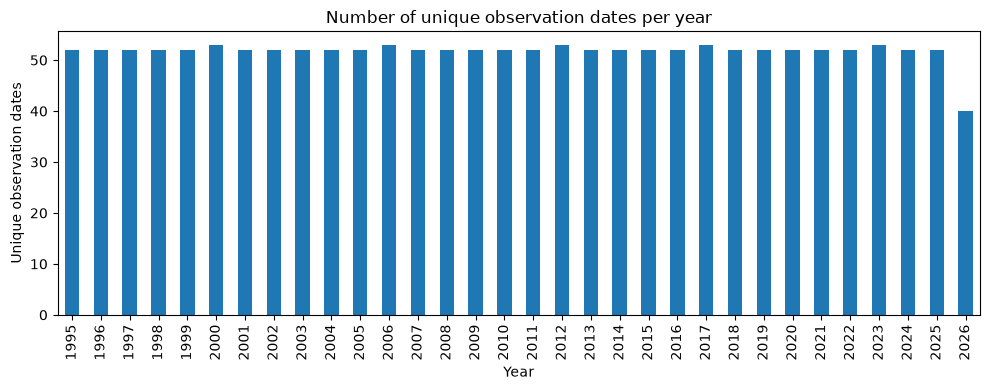

In [9]:
# Count the number of unique observation dates per year
dates_per_year = (df["date_id"].drop_duplicates().dt.year.value_counts().sort_index())

# Plot the temporal coverage of the dataset
plt.figure(figsize=(10, 4))
dates_per_year.plot(kind="bar")

plt.title("Number of unique observation dates per year")
plt.xlabel("Year")
plt.ylabel("Unique observation dates")
plt.tight_layout()
plt.show()

The yearly coverage is almost the same as in Part 1. The main difference is 2026, where the API now contains observations up to 4 October instead of 6 September.

##### `area_type`

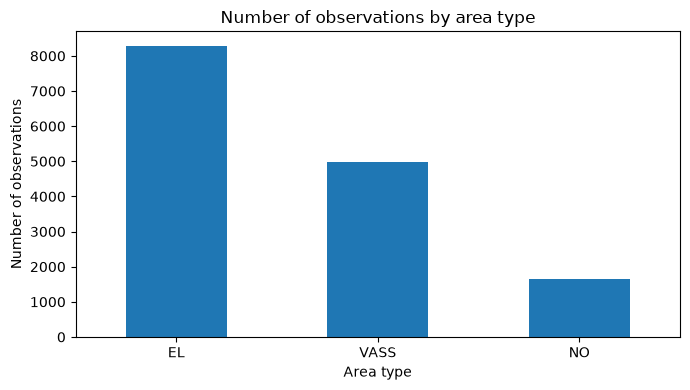

In [10]:
# Count observations for each area type
area_type_counts = df["area_type"].value_counts()

# Plot the frequency of each area type
plt.figure(figsize=(7, 4))
area_type_counts.plot(kind="bar")

plt.title("Number of observations by area type")
plt.xlabel("Area type")
plt.ylabel("Number of observations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The distribution is unchanged from Part 1, with `EL` containing the most observations because it includes five area numbers, compared with three for `VASS` and one for `NO`.

##### `area_number`

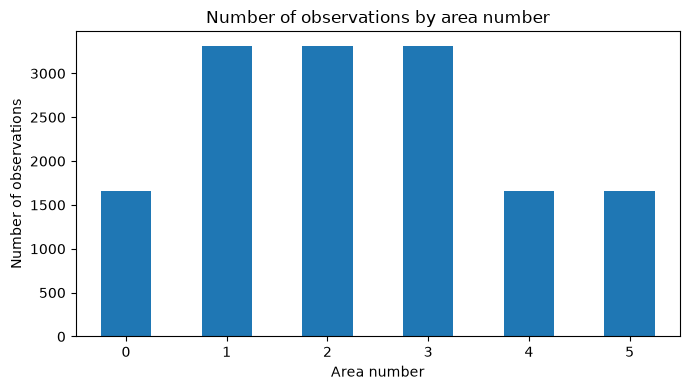

In [11]:
# Count observations for each area number
area_number_counts = df["area_number"].value_counts().sort_index()

# Plot the frequency of each area number
plt.figure(figsize=(7, 4))
area_number_counts.plot(kind="bar")

plt.title("Number of observations by area number")
plt.xlabel("Area number")
plt.ylabel("Number of observations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The distribution is unchanged from Part 1. Area numbers `1`, `2`, and `3` still occur about twice as often as `0`, `4`, and `5`.

##### `iso_year`

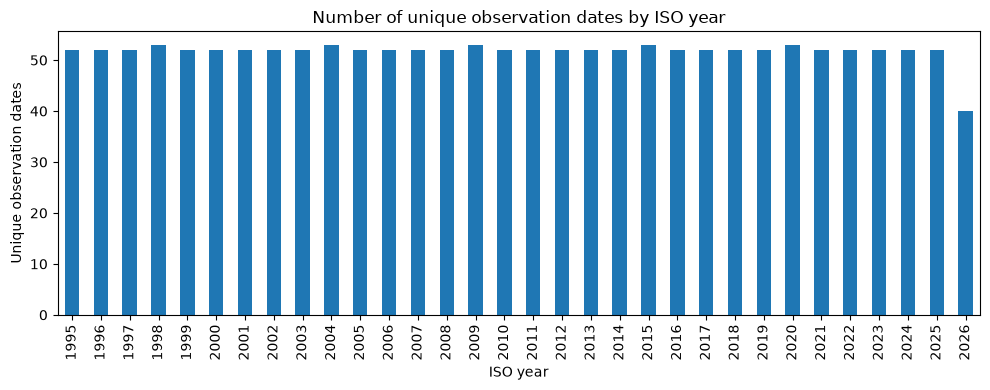

In [12]:
# Count unique observation dates for each ISO year
dates_per_iso_year = (df[["date_id", "iso_year"]].drop_duplicates()
                      ["iso_year"].value_counts().sort_index())

# Plot the number of unique observation dates by ISO year
plt.figure(figsize=(10, 4))
dates_per_iso_year.plot(kind="bar")

plt.title("Number of unique observation dates by ISO year")
plt.xlabel("ISO year")
plt.ylabel("Unique observation dates")
plt.tight_layout()
plt.show()

The distribution is also almost unchanged from Part 1, except that 2026 now contains four additional weekly observations up to 4 October instead of 6 September.

##### `iso_week`

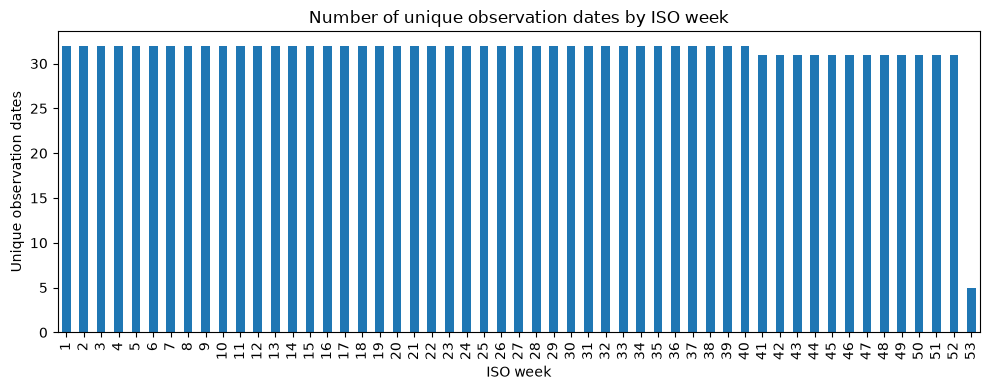

In [13]:
# Count unique observation dates for each ISO week
dates_per_iso_week = (df[["date_id", "iso_week"]].drop_duplicates()
                      ["iso_week"].value_counts().sort_index())

# Plot the number of unique observation dates by ISO week
plt.figure(figsize=(10, 4))
dates_per_iso_week.plot(kind="bar")

plt.title("Number of unique observation dates by ISO week")
plt.xlabel("ISO week")
plt.ylabel("Unique observation dates")
plt.tight_layout()
plt.show()

Compared with Part 1, ISO weeks 37-40 now also contain an observation from 2026 because the API data extends from week 36 to week 40. The distribution for the remaining weeks is unchanged.

##### `reservoir_fill_ratio`

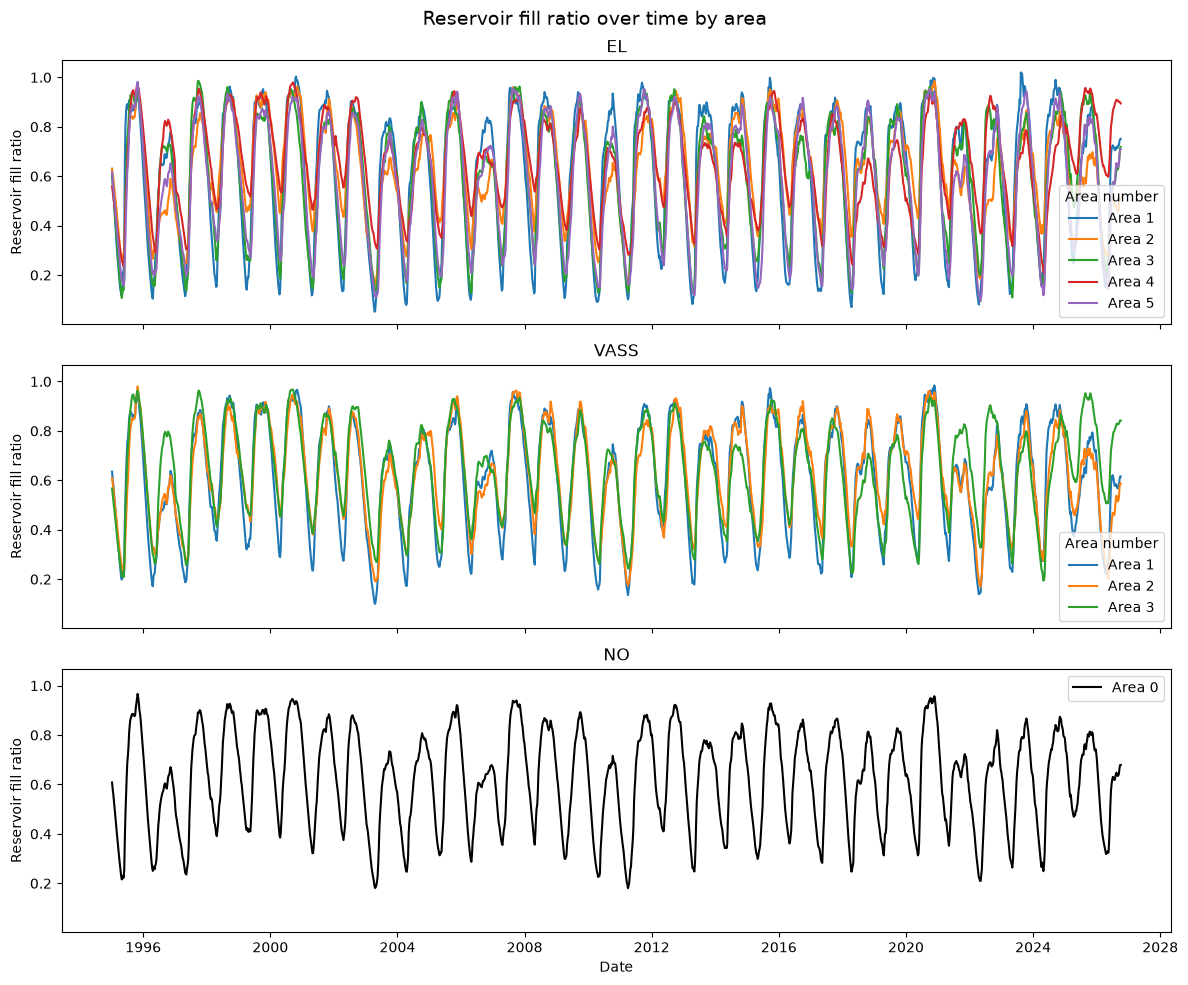

In [14]:
def plot_by_area(data, column, ylabel, title, zero_line=False):
    """Plot a time-series variable by area type and area number."""
    
    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True, sharey=True)

    area_types = ["EL", "VASS", "NO"]

    for ax, area_type in zip(axes, area_types):
        area_data = data[data["area_type"] == area_type]

        for area_number, group in area_data.groupby("area_number"):
            group = group.sort_values("date_id")

            if area_type == "NO":
                ax.plot(group["date_id"], group[column], label=f"Area {area_number}", color="black")
            else:
                ax.plot(group["date_id"], group[column], label=f"Area {area_number}")

        if zero_line:
            ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)

        ax.set_title(area_type)
        ax.set_ylabel(ylabel)

        if area_type == "NO":
            ax.legend()
        else:
            ax.legend(title="Area number")

    axes[-1].set_xlabel("Date")
    fig.suptitle(title, fontsize=14)

    plt.tight_layout()
    plt.show()

plot_by_area(df, "reservoir_fill_ratio", "Reservoir fill ratio", "Reservoir fill ratio over time by area")

The seasonal pattern in reservoir fill ratio remains the same as in Part 1, with no notable change in the relative patterns between areas.

##### `reservoir_capacity_twh`

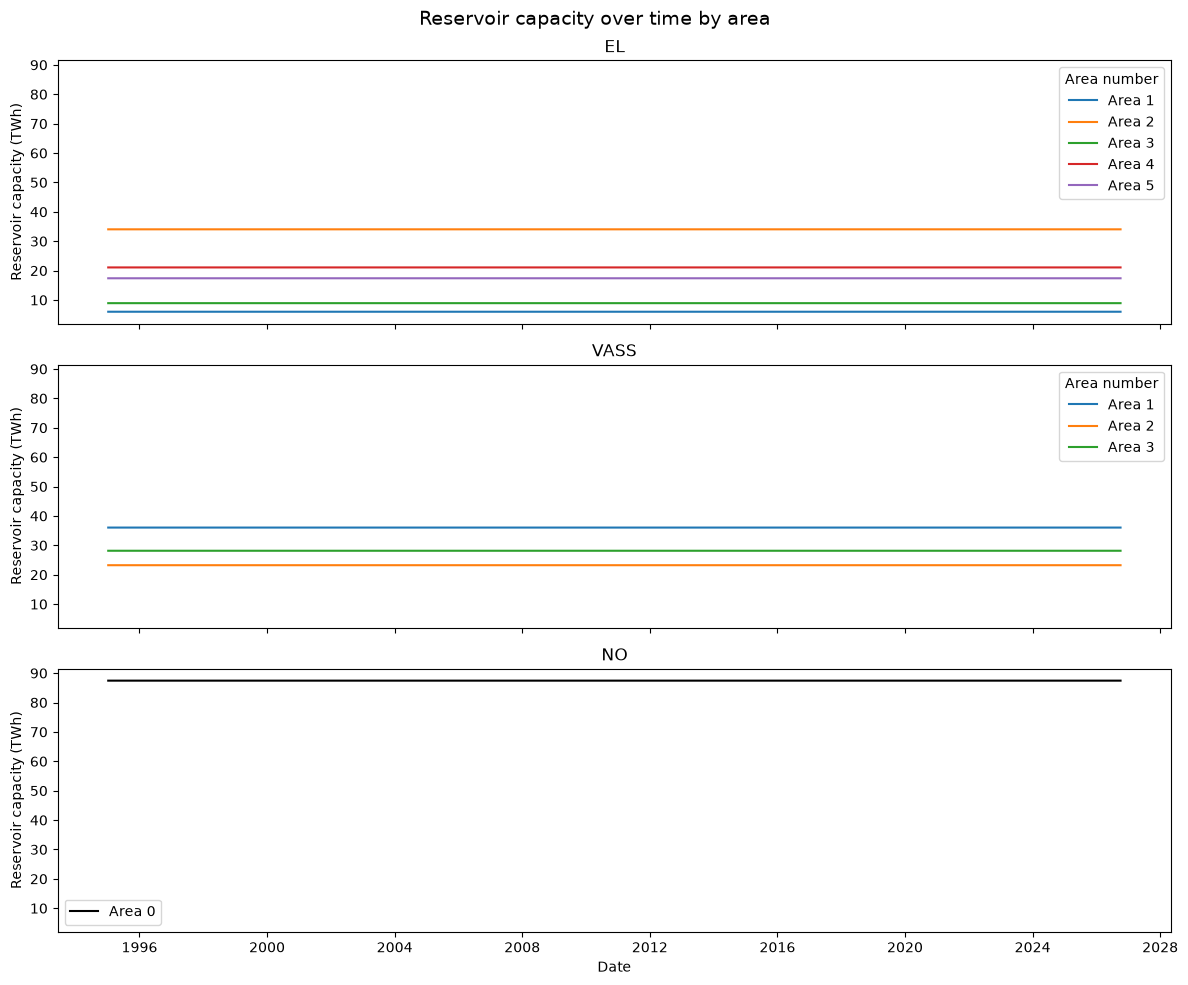

In [15]:
plot_by_area(df, "reservoir_capacity_twh", "Reservoir capacity (TWh)", "Reservoir capacity over time by area")

As in Part 1, reservoir capacity remains nearly constant within each area, and the relative differences in capacity between areas are unchanged.

##### `stored_energy_twh`

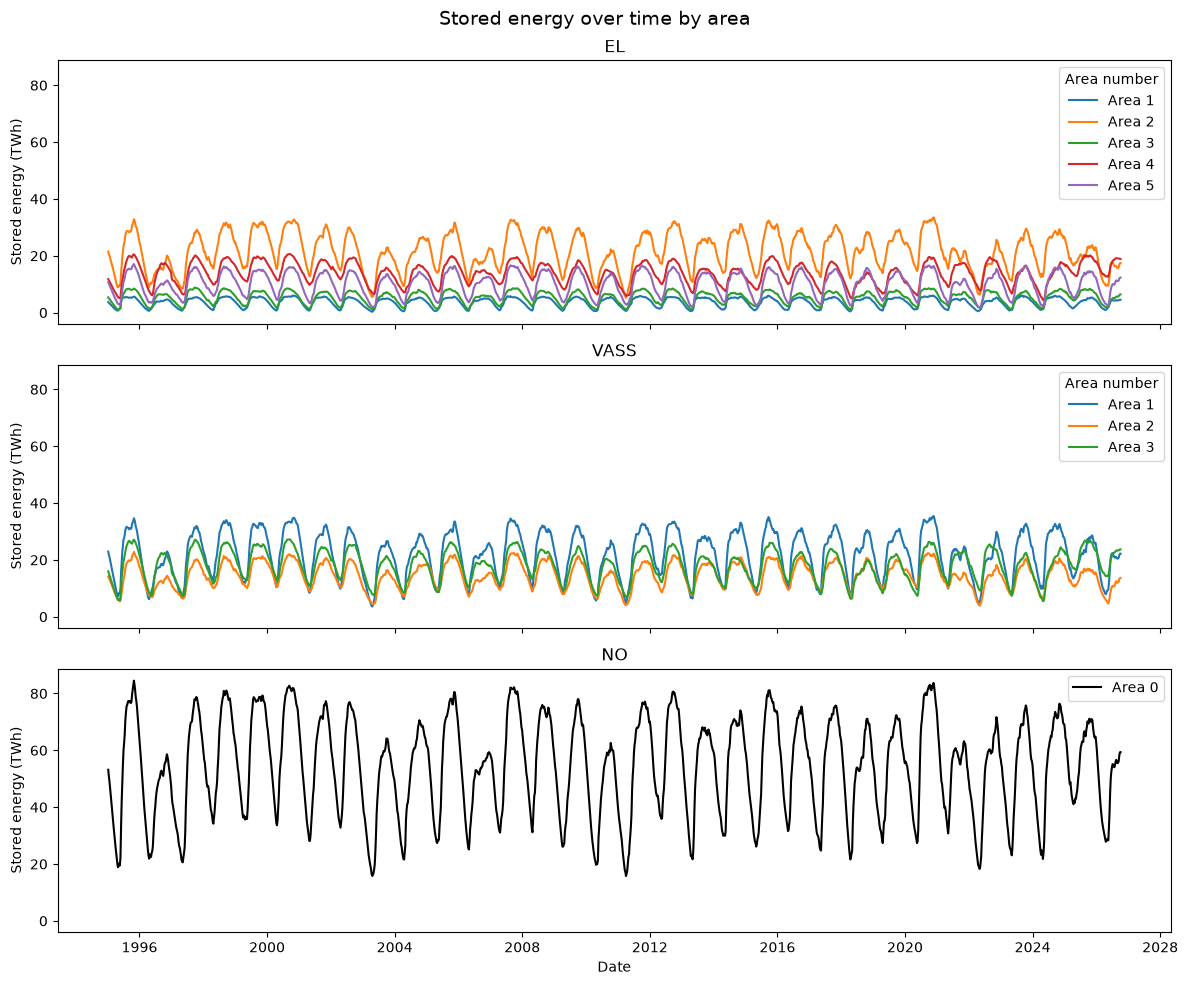

In [16]:
plot_by_area(df, "stored_energy_twh", "Stored energy (TWh)", "Stored energy over time by area")

The stored-energy series reproduces the same area differences and seasonal variation observed in Part 1, now including the latest API observations.

##### `next_publication_date`

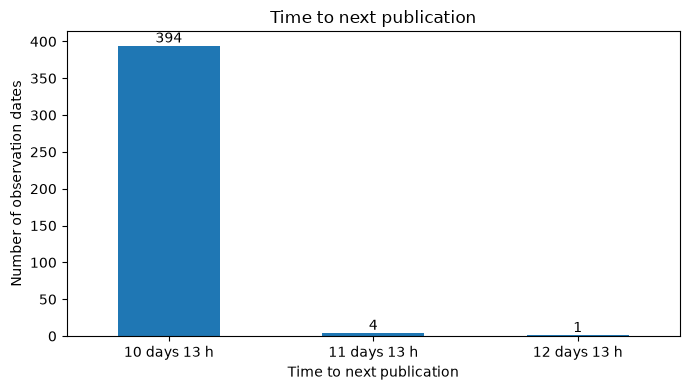

In [17]:
# Prepare one valid publication date for each observation date
publication_data = (df[df["next_publication_date"] != "0001-01-01T00:00:00"]
                    [["date_id", "next_publication_date"]].drop_duplicates().copy())

# Convert publication dates to datetime
publication_data["next_publication_date"] = pd.to_datetime(
    publication_data["next_publication_date"])

# Calculate the publication delay in whole hours
publication_data["publication_delay_hours"] = (
    publication_data["next_publication_date"] - publication_data["date_id"]
    ).dt.total_seconds().div(3600).round().astype(int)

# Create readable labels for the observed delays
publication_data["publication_delay"] = publication_data[
    "publication_delay_hours"].apply(
        lambda hours: f"{hours // 24} days {hours % 24} h")

# Count each publication delay
delay_counts = (publication_data.groupby(["publication_delay_hours", "publication_delay"])
                .size().sort_index())

# Plot the publication-delay frequencies
ax = delay_counts.plot(kind="bar", figsize=(7, 4))

plt.title("Time to next publication")
plt.xlabel("Time to next publication")
plt.ylabel("Number of observation dates")
plt.xticks(range(len(delay_counts)),
           [label for _, label in delay_counts.index], rotation=0)

# Display the exact count above each bar
for i, count in enumerate(delay_counts):
    ax.text(i, count, str(count), ha="center", va="bottom")

plt.tight_layout()
plt.show()

The publication delay pattern remains almost identical to Part 1, but the additional API observations increase the number of dates with the most common delay.

##### `previous_week_reservoir_fill_ratio`

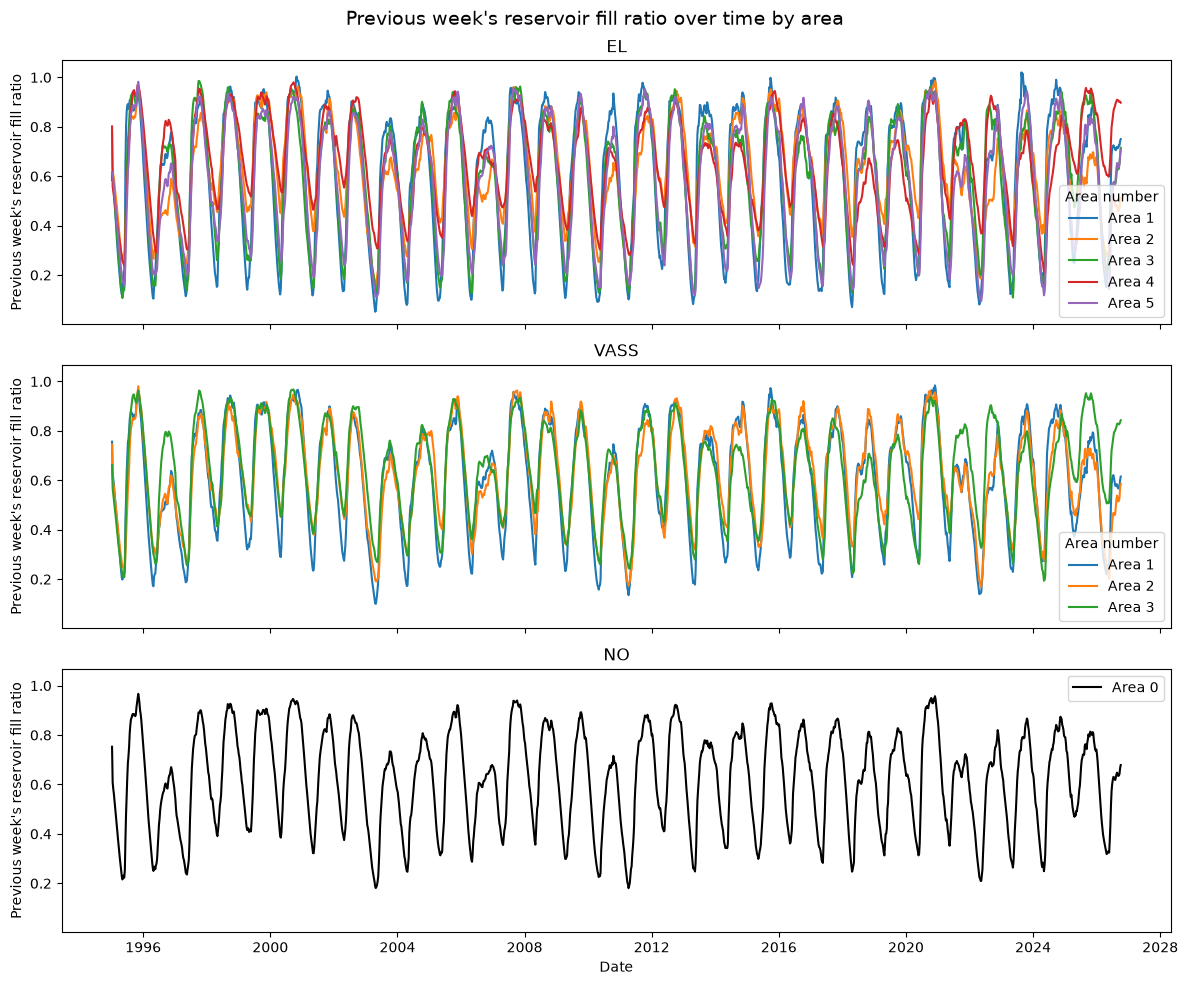

In [18]:
plot_by_area(df, "previous_week_reservoir_fill_ratio", "Previous week's reservoir fill ratio", "Previous week's reservoir fill ratio over time by area")

The previous-week fill ratios show the same behaviour as in Part 1 and continue to closely follow the current fill-ratio series.

##### `reservoir_fill_ratio_change`

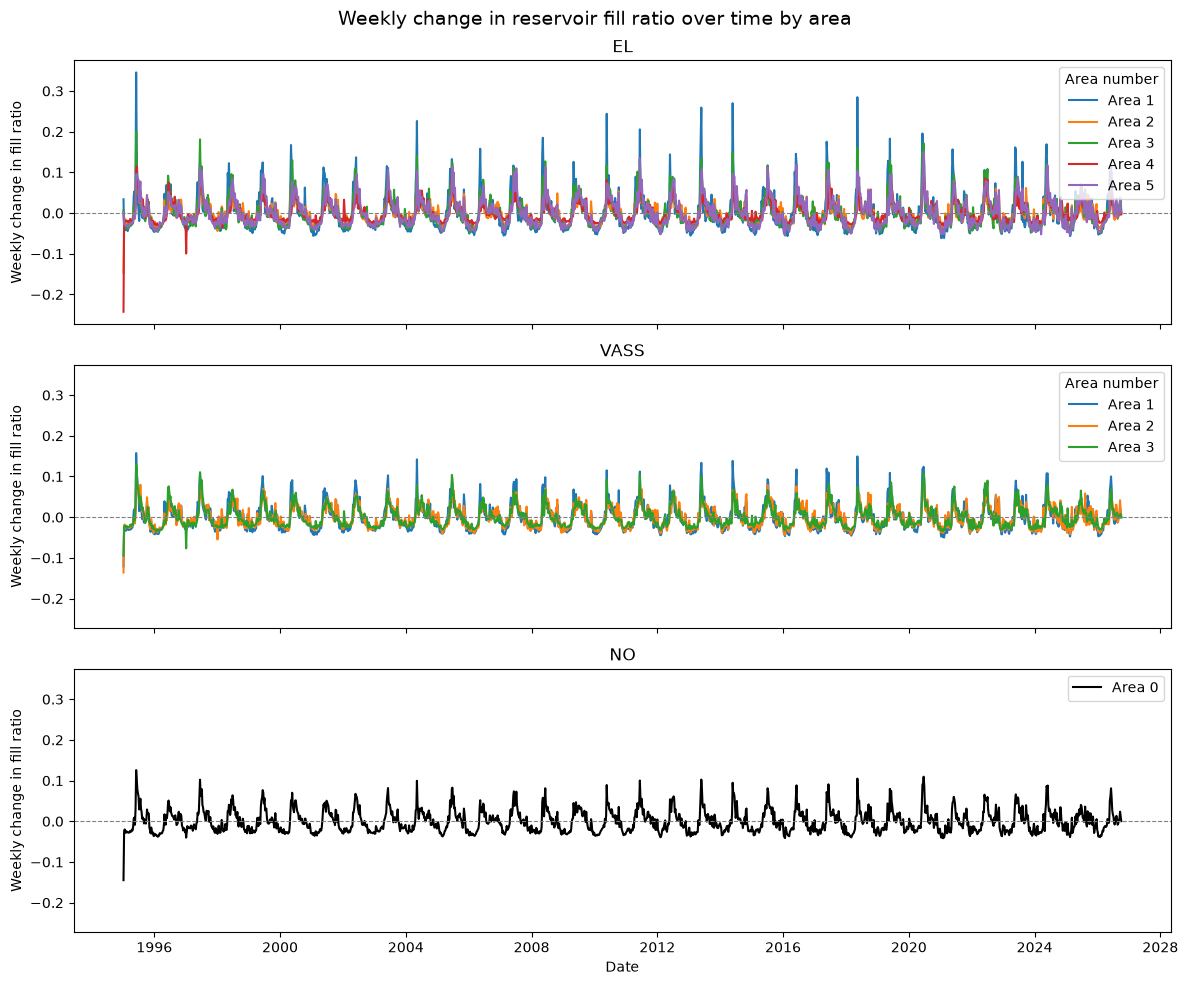

In [19]:
plot_by_area(df, "reservoir_fill_ratio_change", "Weekly change in fill ratio", "Weekly change in reservoir fill ratio over time by area", zero_line=True)

The weekly changes remain centred around zero with alternating periods of filling and depletion, consistent with the pattern seen in Part 1.

#### Combined plot

<div class="alert alert-block alert-info">
<b>Plotting choice:</b> The <code>NO 0</code> series is used to keep the combined plot readable. An alternative would be to plot the combined measurements for all nine area combinations in a 3 × 3 subplot layout, but this would be more crowded and would largely repeat the area-specific visualisations in Section 1.4.
</div>

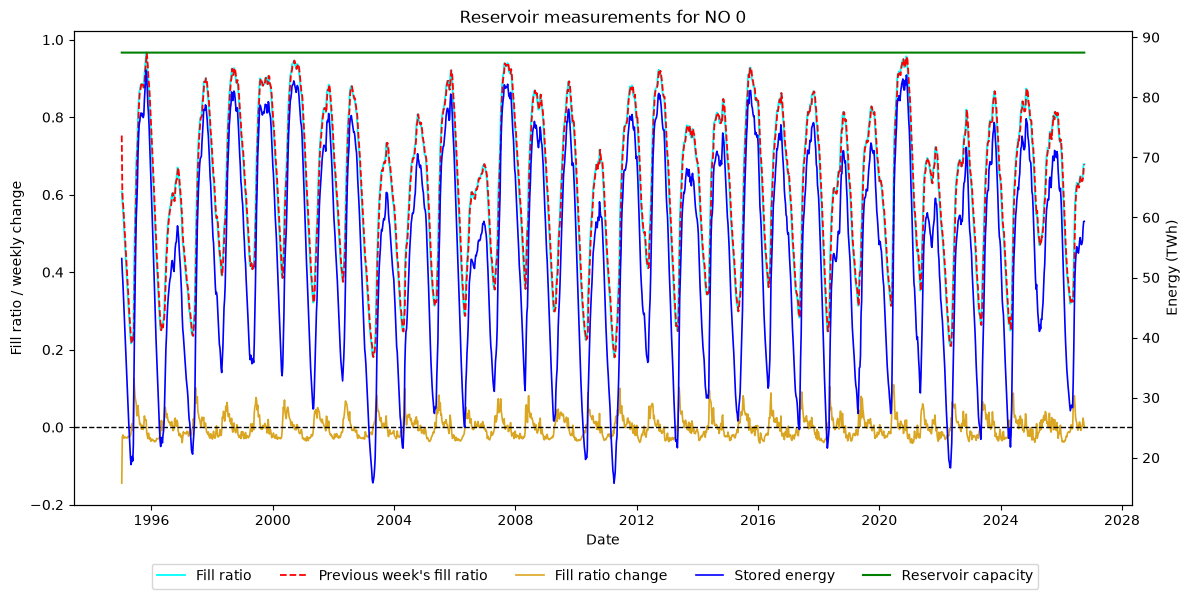

In [20]:
# Select the NO 0 time series and sort it chronologically
combined_data = (df[(df["area_type"] == "NO") & (df["area_number"] == 0)].sort_values("date_id"))

# Create a figure with two y-axes
fig, ax1 = plt.subplots(figsize=(12, 6))
ax2 = ax1.twinx()

# Fill-related variables: left y-axis
ax1.plot(combined_data["date_id"], combined_data["reservoir_fill_ratio"], label="Fill ratio",
         color="cyan", linewidth=1.3)

ax1.plot(combined_data["date_id"], combined_data["previous_week_reservoir_fill_ratio"],
         label="Previous week's fill ratio", color="red", linewidth=1.3, linestyle="--")

ax1.plot(combined_data["date_id"], combined_data["reservoir_fill_ratio_change"],
         label="Fill ratio change", color="goldenrod", linewidth=1.2)

# Add a reference line for positive and negative weekly change
ax1.axhline(y=0, color="black", linestyle="--", linewidth=1)

# Energy-related variables: right y-axis
ax2.plot(combined_data["date_id"], combined_data["stored_energy_twh"],
         label="Stored energy", color="blue", linewidth=1.2)

ax2.plot(combined_data["date_id"], combined_data["reservoir_capacity_twh"],
         label="Reservoir capacity", color="green", linewidth=1.5)

# Title and axis labels
ax1.set_title("Reservoir measurements for NO 0")
ax1.set_xlabel("Date")
ax1.set_ylabel("Fill ratio / weekly change")
ax2.set_ylabel("Energy (TWh)")

# Combine legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

fig.legend(lines1 + lines2, labels1 + labels2, loc="lower center", ncol=5,
           bbox_to_anchor=(0.5, -0.002), frameon=True)

# Leave space for the legend
plt.tight_layout()
plt.subplots_adjust(bottom=0.15)

plt.show()

The combined plot reproduces the Part 1 visualisation using the API data. The overall relationships between the five reservoir variables remain unchanged.

## 4. Streamlit App

The Streamlit app was updated to retrieve the reservoir data directly from the NVE Magasinstatistikk API instead of the local CSV file. Data loading is still handled by the shared `load_data()` function, so the existing reservoir pages can use the new data source without changing how they access the data.

In [21]:
!cat ../modules/data.py

import pandas as pd
import requests
import streamlit as st


@st.cache_data
def load_data():
    """Retrieve, prepare and cache the NVE Magasinstatistikk reservoir dataset."""
    url = ("https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData")
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    
    df = pd.DataFrame(response.json())

    # Rename the original column headers to English names
    df = df.rename(columns={
        "dato_Id": "date_id",
        "omrType": "area_type",
        "omrnr": "area_number",
        "iso_aar": "iso_year",
        "iso_uke": "iso_week",
        "fyllingsgrad": "reservoir_fill_ratio",
        "kapasitet_TWh": "reservoir_capacity_twh",
        "fylling_TWh": "stored_energy_twh",
        "neste_Publiseringsdato": "next_publication_date",
        "fyllingsgrad_forrige_uke": "previous_week_reservoir_fill_ratio",
        "endring_fyllingsgrad": "reservoir_fill_ratio_change"
    })
    
    df["date_id"

### 4.1 Magasinstatistikk API page

The `HentOffentligData` endpoint returns the complete public reservoir dataset and does not accept query parameters. The dataset is therefore retrieved through the shared `load_data()` function and cached with `st.cache_data`. The same basic preprocessing as in Part 1 is retained, including renaming the columns to English.

<div style="background-color:#EAF2F7; border-left:5px solid #3E7FA6; padding:12px 16px; border-radius:6px;">

<h2>AI usage</h2>

To be filled out

</div>

## Project log

I started Part 2 by exploring the Magasinstatistikk API from NVE in the Jupyter Notebook and comparing the returned data with the reservoir dataset from Part 1. The API returned the same overall structure, but included four additional weeks of observations. I also checked the geographical area definitions using the `HentOmråder` endpoint and compared them with the area combinations actually present in the reservoir data. Once I had confirmed how the API data was structured, I recreated the plots from Part 1 and checked that the main patterns were still the same.

I then updated the Streamlit app to use the NVE API instead of the local CSV file. Since both the Data Table and Data Plot pages already used the shared `load_data()` function, I did not need to rewrite the individual pages. The `HentOffentligData` endpoint returns the complete public dataset and does not accept query parameters, so I cache the downloaded data with `st.cache_data` and filter it later in the app. I keep the same basic preprocessing as in Part 1, including renaming the columns to English. After checking that the existing pages still worked correctly with the API data, I removed the old `reservoirs.csv` file from the project.

To be filled out...